In [11]:
!pip install kaggle

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [12]:
# configuring the path of Kaggle.json file
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [13]:
!kaggle competitions download -c dogs-vs-cats

 98% 798M/812M [00:06<00:00, 183MB/s]
100% 812M/812M [00:06<00:00, 138MB/s]


In [14]:
!ls

dogs-vs-cats.zip  kaggle.json  sample_data


In [15]:
# extracting the compressed dataset
from zipfile import ZipFile

dataset = '/content/dogs-vs-cats.zip'

with ZipFile(dataset, 'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [16]:
# extracting the compressed dataset
from zipfile import ZipFile

dataset = '/content/train.zip'

with ZipFile(dataset, 'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [17]:
import os 

path, dirs, files = next(os.walk('/content/train'))
file_count=len(files)
print("Number of images",file_count)

Number of images 25000


In [18]:
file_name=os.listdir("/content/train")
print(file_name)

['dog.6862.jpg', 'dog.4231.jpg', 'dog.9963.jpg', 'dog.5934.jpg', 'cat.5539.jpg', 'dog.229.jpg', 'cat.8338.jpg', 'dog.3638.jpg', 'cat.6341.jpg', 'dog.5285.jpg', 'dog.5472.jpg', 'cat.8330.jpg', 'dog.7444.jpg', 'cat.8956.jpg', 'cat.8139.jpg', 'dog.4426.jpg', 'cat.11169.jpg', 'dog.1685.jpg', 'dog.1884.jpg', 'cat.4863.jpg', 'dog.6865.jpg', 'dog.2590.jpg', 'cat.5152.jpg', 'cat.7812.jpg', 'cat.1138.jpg', 'dog.6482.jpg', 'cat.5847.jpg', 'dog.1981.jpg', 'cat.2250.jpg', 'dog.5235.jpg', 'cat.532.jpg', 'cat.10995.jpg', 'dog.4320.jpg', 'cat.12069.jpg', 'dog.3831.jpg', 'cat.7326.jpg', 'cat.5772.jpg', 'dog.10667.jpg', 'cat.7188.jpg', 'cat.214.jpg', 'dog.11535.jpg', 'cat.7975.jpg', 'dog.3040.jpg', 'dog.513.jpg', 'dog.3207.jpg', 'dog.1957.jpg', 'dog.6235.jpg', 'cat.6400.jpg', 'dog.6871.jpg', 'cat.8603.jpg', 'cat.6012.jpg', 'dog.3720.jpg', 'dog.7447.jpg', 'cat.5317.jpg', 'dog.11477.jpg', 'dog.6417.jpg', 'cat.9228.jpg', 'cat.5830.jpg', 'cat.11280.jpg', 'cat.10628.jpg', 'cat.8618.jpg', 'cat.11933.jpg', 'c

In [19]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt 
import matplotlib.image as mpimg
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow 

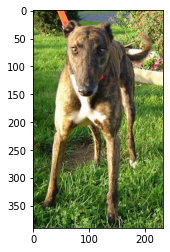

In [20]:
img=mpimg.imread("/content/train/dog.5934.jpg")
imgplt=plt.imshow(img)
plt.show()

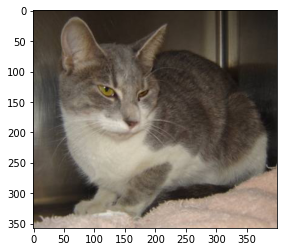

In [21]:
img=mpimg.imread("/content/train/cat.4352.jpg")
imgplt=plt.imshow(img)
plt.show()

In [22]:
file_names=os.listdir("/content/train")

for i in range(5):
  name=file_names[i]
  print(name[0:3])

dog
dog
dog
dog
cat


In [23]:
file_names=os.listdir("/content/train/")

dog_count=0
cat_count=0

for img_file in file_names:
  name=img_file[0:3]
  if name=="dog":
    dog_count +=1
  else:
    cat_count +=1

print('Number of dog images =', dog_count)
print('Number of cat images =', cat_count)

Number of dog images = 12500
Number of cat images = 12500


In [24]:
os.mkdir('/content/image resized')


In [25]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [40]:
original_folder = '/content/train/'
resized_folder = '/content/image resized/'

for i in range(2000):

  filename = os.listdir(original_folder)[i]
  img_path = original_folder+filename

  img = Image.open(img_path)
  img = img.resize((224, 224))
  img = img.convert('RGB')

  newImgPath = resized_folder+filename
  img.save(newImgPath)

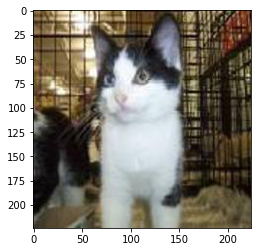

In [42]:
img = mpimg.imread('/content/image resized/cat.1000.jpg')
imgplt = plt.imshow(img)
plt.show()

In [28]:
filenames = os.listdir('/content/image resized/')


labels=[]
for i in range(2000):
  file_name=filenames[i]
  label=file_name[0:3]
  if label=='dog':
    labels.append(1)
  else:
    labels.append(0)

In [29]:
print(file_names[0:5])

['dog.6862.jpg', 'dog.4231.jpg', 'dog.9963.jpg', 'dog.5934.jpg', 'cat.5539.jpg']


In [30]:
print(len(filenames))

2000


In [31]:
print(labels[0:5])
print(len(labels))

[1, 1, 1, 1, 0]
2000


In [32]:
values,counts=np.unique(labels,return_counts=True)
print(values)
print(counts)

[0 1]
[ 983 1017]


In [33]:
import cv2
import glob

In [44]:
image_directory = '/content/image resized/'
image_extension = ['png', 'jpg']

files = []

[files.extend(glob.glob(image_directory + '*.' + e)) for e in image_extension]

dog_cat_images = np.asarray([cv2.imread(file) for file in files])

In [45]:
print(dog_cat_images)

[[[[212 196 190]
   [210 194 188]
   [168 152 146]
   ...
   [123 128 153]
   [123 130 155]
   [124 131 156]]

  [[210 194 188]
   [216 200 194]
   [175 159 153]
   ...
   [130 136 159]
   [131 137 160]
   [132 139 159]]

  [[205 189 183]
   [222 206 200]
   [184 170 164]
   ...
   [136 140 158]
   [137 141 159]
   [137 144 159]]

  ...

  [[ 58  62  57]
   [ 69  73  68]
   [ 95  96  92]
   ...
   [ 53  76  84]
   [ 36  58  69]
   [ 26  48  59]]

  [[ 56  60  55]
   [ 64  68  63]
   [ 85  86  82]
   ...
   [ 54  76  87]
   [ 38  60  71]
   [ 27  49  60]]

  [[ 57  61  56]
   [ 61  65  60]
   [ 78  79  75]
   ...
   [ 56  78  89]
   [ 40  62  73]
   [ 29  51  62]]]


 [[[ 72  78  97]
   [ 75  81 100]
   [ 77  83 102]
   ...
   [214 167  99]
   [227 152  83]
   [213 125  54]]

  [[ 71  77  96]
   [ 74  80  99]
   [ 77  83 102]
   ...
   [211 168 101]
   [227 156  88]
   [203 118  48]]

  [[ 70  76  95]
   [ 73  79  98]
   [ 77  83 102]
   ...
   [187 149  85]
   [214 150  85]
   [187 112

In [46]:
type(dog_cat_images)

numpy.ndarray

In [47]:
print(dog_cat_images.shape)

(2000, 224, 224, 3)


In [52]:
X = dog_cat_images
Y = np.asarray(labels)

In [53]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [54]:
X_train_scaled = X_train/255

X_test_scaled = X_test/255

In [55]:
import tensorflow as tf
import tensorflow_hub as hub

In [57]:
mobilenet_model = 'https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4'
pretrained_model =hub.KerasLayer(mobilenet_model,input_shape=(224,224,3),trainable=False)

In [58]:
num_of_classes = 2

model=tf.keras.Sequential([
    pretrained_model,
    tf.keras.layers.Dense(num_of_classes)



])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense (Dense)               (None, 2)                 2562      
                                                                 
Total params: 2,260,546
Trainable params: 2,562
Non-trainable params: 2,257,984
_________________________________________________________________


In [59]:
model.compile(
    optimizer = 'adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics = ['acc']
)

In [60]:
model.fit(X_train_scaled, Y_train, epochs=5)

Epoch 1/5
50/50 [==============================] - 54s 950ms/step - loss: 0.2457 - acc: 0.8938
Epoch 2/5
50/50 [==============================] - 47s 946ms/step - loss: 0.0734 - acc: 0.9762
Epoch 3/5
50/50 [==============================] - 46s 923ms/step - loss: 0.0515 - acc: 0.9831
Epoch 4/5
50/50 [==============================] - 46s 919ms/step - loss: 0.0407 - acc: 0.9881
Epoch 5/5
50/50 [==============================] - 46s 921ms/step - loss: 0.0325 - acc: 0.9906


In [61]:
score,acc=model.evaluate(X_test_scaled,Y_test)

13/13 [==============================] - 16s 1s/step - loss: 0.0557 - acc: 0.9775


In [62]:
print(score)
print(acc)

0.05565973371267319
0.9775000214576721


Path of the image to be predicted/content/The_Science-Backed_Benefits_of_Being_a_Dog_Owner.jpg


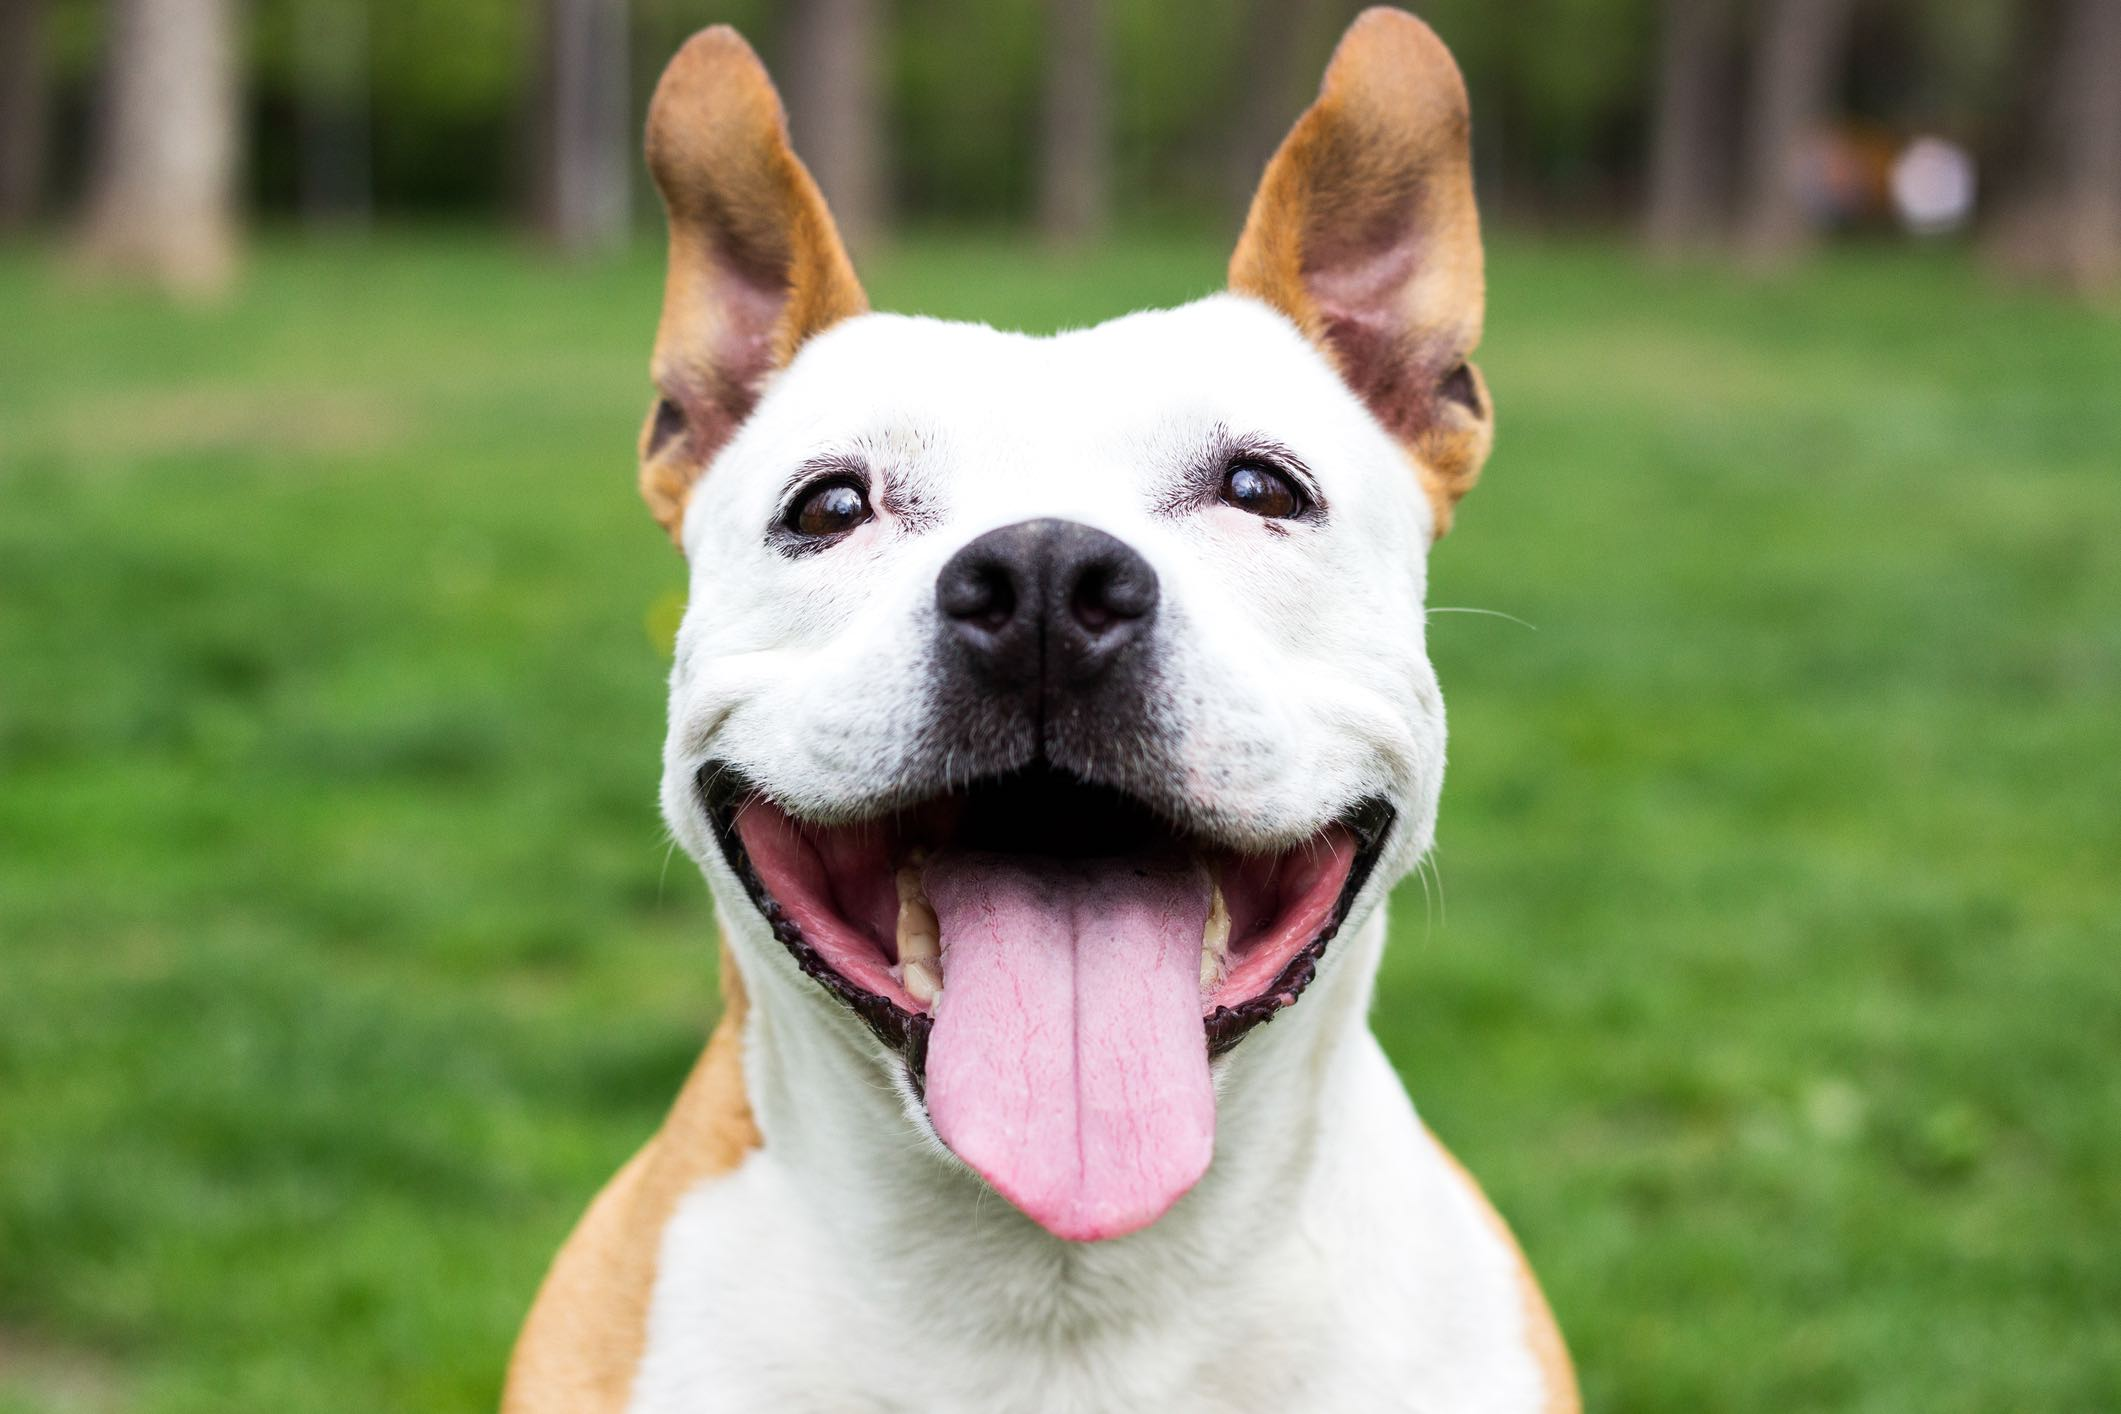

1/1 [==============================] - 1s 844ms/step
[[-1.4541423  3.6379676]]
1
The image represent dog


In [69]:
input_image_path=input("Path of the image to be predicted")
input_image=cv2.imread(input_image_path)
cv2_imshow(input_image)
input_image_resize=cv2.resize(input_image,(224,224))
input_image_scaled=input_image_resize/255

image_reshaped=np.reshape(input_image_scaled,[1,224,224,3])

input_predicton=model.predict(image_reshaped)
print(input_predicton)

input_pred_label=np.argmax(input_predicton)

print(input_pred_label)

if input_pred_label==0:
  print("The image represent cat")
else:
  print("The image represent dog")

Path of the image to be predicted/content/3683.jpg


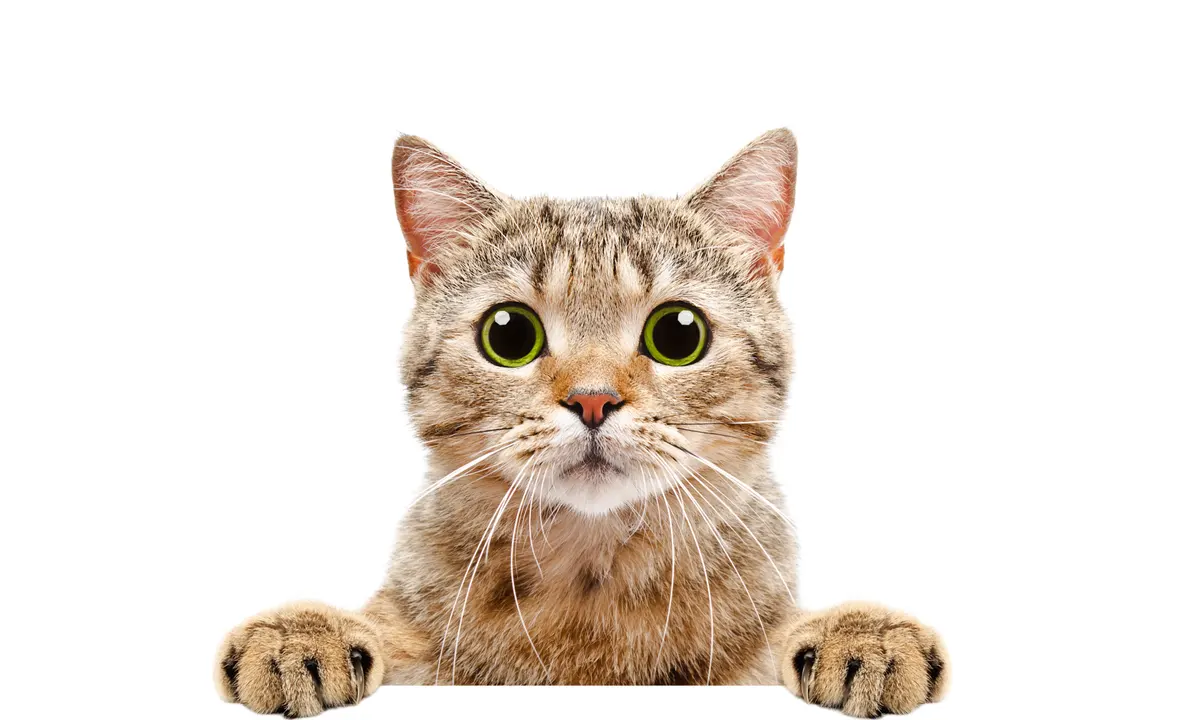

1/1 [==============================] - 0s 116ms/step
[[ 2.2825685 -2.558567 ]]
0
The image represent cat


In [70]:
input_image_path=input("Path of the image to be predicted")
input_image=cv2.imread(input_image_path)
cv2_imshow(input_image)
input_image_resize=cv2.resize(input_image,(224,224))
input_image_scaled=input_image_resize/255

image_reshaped=np.reshape(input_image_scaled,[1,224,224,3])

input_predicton=model.predict(image_reshaped)
print(input_predicton)

input_pred_label=np.argmax(input_predicton)

print(input_pred_label)

if input_pred_label==0:
  print("The image represent cat")
else:
  print("The image represent dog")